In [1]:
import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("student.zip") as inner_zip:
        with zipfile.ZipFile(inner_zip) as data_zip:
            df = pd.read_csv(data_zip.open("student-mat.csv"), sep=";")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
df.head()

Dataset loaded successfully!
Rows and columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset size: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Number of duplicate rows:
0


In [4]:
print("Average final grade:", round(df["G3"].mean(), 2))
print("Highest final grade:", df["G3"].max())
print("Lowest final grade:", df["G3"].min())

print("\nAverage final grade by study time:")
print(df.groupby("studytime")["G3"].mean().round(2))

Average final grade: 10.42
Highest final grade: 20
Lowest final grade: 0

Average final grade by study time:
studytime
1    10.05
2    10.17
3    11.40
4    11.26
Name: G3, dtype: float64


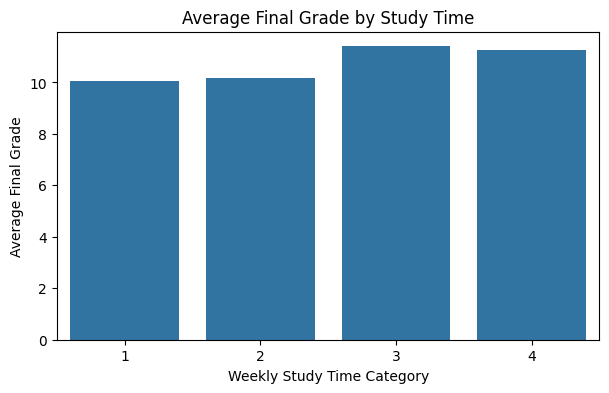

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="studytime", y="G3", errorbar=None)

plt.title("Average Final Grade by Study Time")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Average Final Grade")
plt.show()

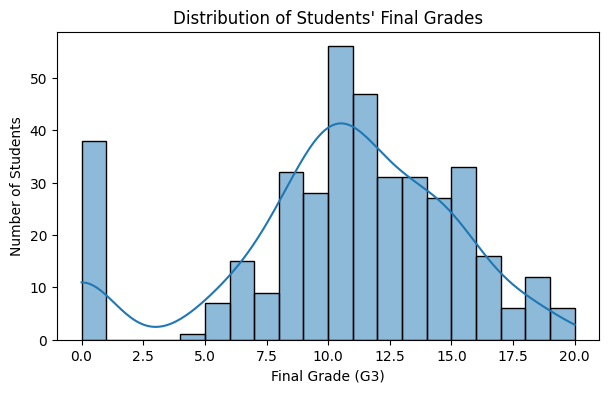

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="G3", bins=20, kde=True)

plt.title("Distribution of Students' Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

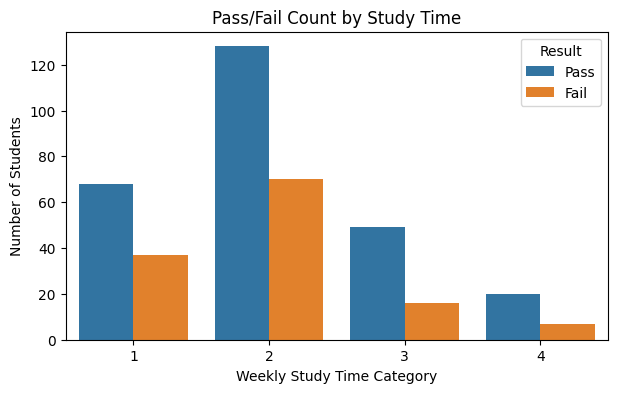

In [7]:
df["Result"] = df["G3"].apply(lambda grade: "Pass" if grade >= 10 else "Fail")

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="studytime", hue="Result")

plt.title("Pass/Fail Count by Study Time")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Number of Students")
plt.show()

In [8]:
# Create the target: 1 = Pass, 0 = Fail
df["pass"] = (df["G3"] >= 10).astype(int)

# Keep student information as input features
# Remove grades so the model doesn't use grades to predict the result
X = df.drop(columns=["G1", "G2", "G3", "pass", "Result"], errors="ignore")

# The result we want the model to predict
y = df["pass"]

# Convert text categories into numeric columns
X = pd.get_dummies(X, drop_first=True)

print("Features ready:", X.shape)
print("\nPass/fail counts:")
print(y.value_counts().rename(index={0: "Fail", 1: "Pass"}))

Features ready: (395, 39)

Pass/fail counts:
pass
Pass    265
Fail    130
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 316
Testing records: 79


In [11]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy: 0.684

Classification Report:
              precision    recall  f1-score   support

        Fail       0.55      0.23      0.32        26
        Pass       0.71      0.91      0.79        53

    accuracy                           0.68        79
   macro avg       0.63      0.57      0.56        79
weighted avg       0.65      0.68      0.64        79


Confusion Matrix:
[[ 6 20]
 [ 5 48]]


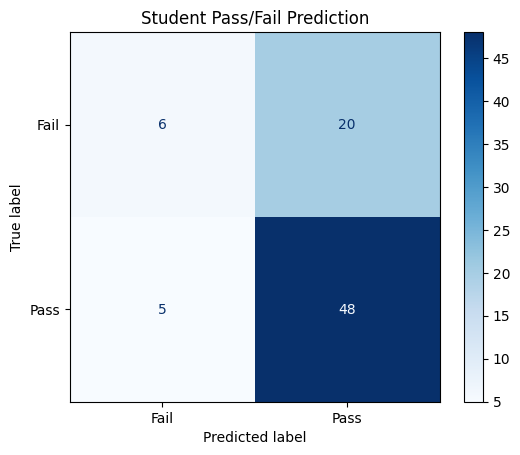

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Fail", "Pass"],
    cmap="Blues"
)

plt.title("Student Pass/Fail Prediction")
plt.show()

failures    0.094421
absences    0.093302
goout       0.056362
age         0.049519
health      0.046366
freetime    0.043550
Walc        0.042060
Fedu        0.041583
Medu        0.037975
famrel      0.033760
dtype: float64


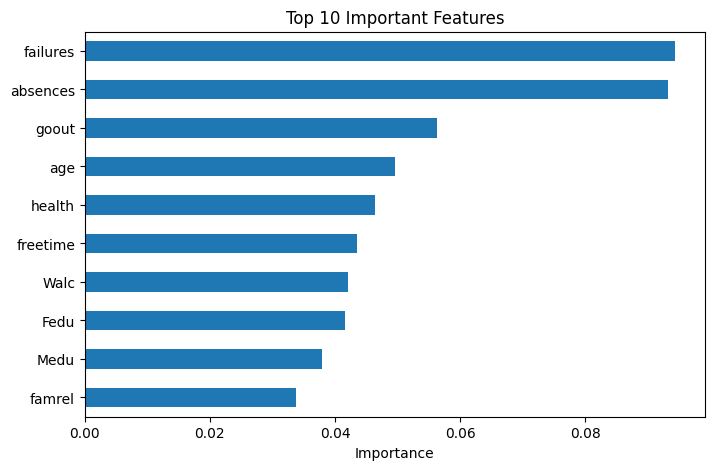

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.head(10))

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.show()

Conclusion: This project analyzed the UCI Student Performance dataset and explored patterns in students’ final grades. A Random Forest classification model was trained to predict pass/fail status using student information, excluding the grade columns. The model achieved an accuracy of [your accuracy] on the test data. The most important features reported by the model were [top features from Step 13]. These results describe patterns in this dataset and should not be interpreted as proof of cause and effect.